# 01 · Baseline Data Exploration
**AMANAH Trust Layer — EnergyMind Tunisia (IEEE TSYP14)**

This notebook explores the **clean baseline** produced by `src/simulate.py`: a physics-informed
low-voltage smart-metered neighborhood feeder at 15-minute resolution for July (Tunisian summer peak).

It documents the physical backbone that the anomaly injector (`02`) and the trust layer build on.

**To regenerate:** `python src/simulate.py`

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('..'))
pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 30)
RAW = os.path.abspath('../data/raw/amanah_baseline_clean.csv')
if not os.path.exists(RAW):
    print('baseline missing -> running src/simulate.py to regenerate ...')
    os.system('cd .. && python src/simulate.py')
print('baseline exists:', os.path.exists(RAW))

baseline exists: True


## 1 · Load and shape
Long format: one row per `(timestamp, node_id, channel)`. Channels are the signals Goal 1 names:
voltage (V), current (I), active power (P), reactive power (Q), power factor (PF), frequency (f).

In [2]:
df = pd.read_csv(RAW, parse_dates=['timestamp'])
print('rows          :', len(df))
print('time range    :', df.timestamp.min(), '->', df.timestamp.max())
print('nodes         :', df.node_id.nunique())
print('channels      :', sorted(df.channel.unique()))
print('NaN values    :', int(df.value.isna().sum()))
print('\nnode kinds:')
print(df.groupby('kind').node_id.nunique().to_string())
print('\nprovenance tags:')
print(df.groupby('provenance').node_id.nunique().to_string())

rows          : 622080
time range    : 2026-07-01 00:00:00 -> 2026-07-30 23:45:00
nodes         : 36
channels      : ['I', 'P', 'PF', 'Q', 'V', 'f']
NaN values    : 0

node kinds:
kind
feeder_head     1
household      24
load            3
pv              8

provenance tags:
provenance
feeder_head     1
pv_inverter     8
smart_meter    24
submeter        3


## 2 · Physical sanity checks
Before trusting the baseline we verify three invariants that the trust layer will later rely on:
1. per-node energy balance `|P| = V·I·PF`,
2. the feeder head equals the net of all children (loads minus PV generation),
3. realistic LV voltage / power-factor / frequency bands.

In [3]:
wide = df.pivot_table(index=['timestamp','node_id'], columns='channel', values='value').reset_index()
recon = (wide.P.abs() - wide.V*wide.I*wide.PF/1000.0).abs()
child = df[(df.node_id!='FEEDER_HEAD')&(df.channel=='P')].groupby('timestamp').value.sum()
head = df[(df.node_id=='FEEDER_HEAD')&(df.channel=='P')].set_index('timestamp').value
imbalance = (head - child).abs()
print('energy-balance |P|-|V·I·PF| max err :', round(recon.max(), 6))
print('feeder-head - sum(children) max err :', round(imbalance.max(), 6))
v = df[df.channel=='V'].value; pf = df[df.channel=='PF'].value; f = df[df.channel=='f'].value
print('voltage  band :', round(v.min(),1), '-', round(v.max(),1), 'V')
print('PF       band :', round(pf.min(),2), '-', round(pf.max(),2))
print('freq     band :', round(f.min(),2), '-', round(f.max(),2), 'Hz')

energy-balance |P|-|V·I·PF| max err : 0.0
feeder-head - sum(children) max err : 0.0
voltage  band : 213.7 - 231.8 V
PF       band : 0.8 - 0.98
freq     band : 49.91 - 50.1 Hz


## 3 · Daily load shape
Aggregate neighborhood load shows the expected morning peak, evening peak, and a midday
air-conditioning hump typical of a Tunisian summer day.

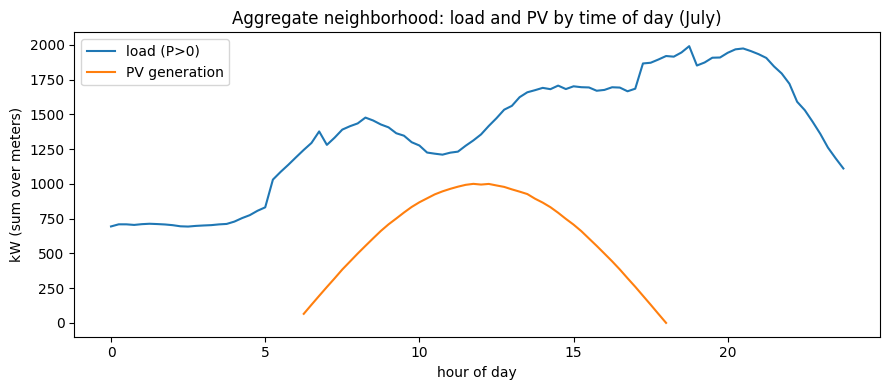

In [4]:
agg = df[(df.node_id!='FEEDER_HEAD')&(df.channel=='P')].copy()
agg['tod'] = agg.timestamp.dt.hour + agg.timestamp.dt.minute/60
load = agg[agg.value>0].groupby(agg.tod.round(2)).value.sum()
gen = agg[agg.value<0].groupby(agg.tod.round(2)).value.sum().abs()
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(load.index, load.values, label='load (P>0)', color='#1f77b4')
ax.plot(gen.index, gen.values, label='PV generation', color='#ff7f0e')
ax.set_xlabel('hour of day'); ax.set_ylabel('kW (sum over meters)'); ax.legend()
ax.set_title('Aggregate neighborhood: load and PV by time of day (July)')
plt.tight_layout(); plt.show()

## 4 · Feeder head vs sum of children
Net import at the feeder head should track the sum of children (load − PV). The tight overlay is
the **physical reference** that lets the trust layer catch a meter lying: if one node's reading is
wrong, it no longer sums to the (independently measured) head.

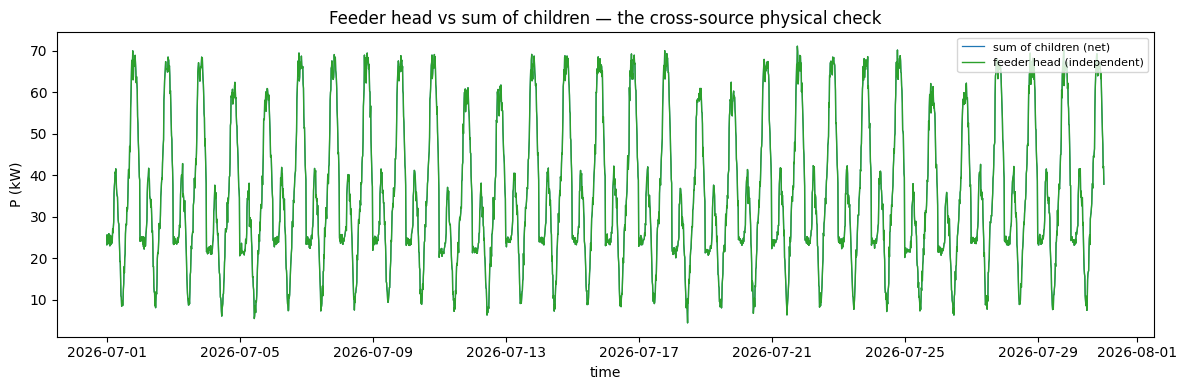

In [5]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(child.index, child.values, lw=0.9, label='sum of children (net)', color='#1f77b4')
ax.plot(head.index, head.values, lw=1.0, label='feeder head (independent)', color='#2ca02c')
ax.set_xlabel('time'); ax.set_ylabel('P (kW)'); ax.legend(loc='upper right', fontsize=8)
ax.set_title('Feeder head vs sum of children — the cross-source physical check')
plt.tight_layout(); plt.show()

---
**Baseline takeaways**
- 30 days × 15-min × 36 nodes × 6 channels, zero NaNs.
- Physical invariants hold to numerical precision, so any deviation introduced later is a *signal*.
- The feeder head is an **independent observation** of the same reality the meters measure — the
  foundation of the provenance-aware trust score.

Next: **`02_anomaly_injection.ipynb`** documents how the five anomaly classes are generated.